# 📊 Trực quan hóa Dữ liệu (EDA & Visualization)

---

🎯 **Mục tiêu**

Khám phá và trực quan hóa các đặc trưng chính của dataset tương tác AI, cung cấp góc nhìn đa chiều về hành vi sử dụng và xu hướng phát triển qua thời gian.

1. **Xu hướng Tăng trưởng theo Năm:** Khảo sát sự dịch chuyển quy mô dữ liệu qua từng năm, làm nổi bật giai đoạn bùng nổ của các công cụ AI.
2. **Tỷ lệ Ngôn ngữ Lập trình:** Thống kê thị phần và so sánh tương quan giữa `python` và `js` trong toàn bộ dataset.
3. **Phân bố theo Thời gian (Giờ & Thứ):** Phân tích khung giờ cao điểm và ngày trong tuần (`0 - 23 UTC+0`) khi người dùng tương tác nhiều nhất.


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

try:
    import missingno as msno
    HAS_MSNO = True
except ImportError:
    HAS_MSNO = False

DATA_PATH = "../data/processed/cleaned_commits_data_final.csv"
df_raw = pd.read_csv(DATA_PATH, low_memory=False)
print(f"✅ Đã tải dữ liệu: {df_raw.shape[0]:,} hàng × {df_raw.shape[1]} cột")

✅ Đã tải dữ liệu: 33,917 hàng × 10 cột


---
# BLOCK 1 — Khảo sát số lượng và sự tăng trưởng theo năm
---

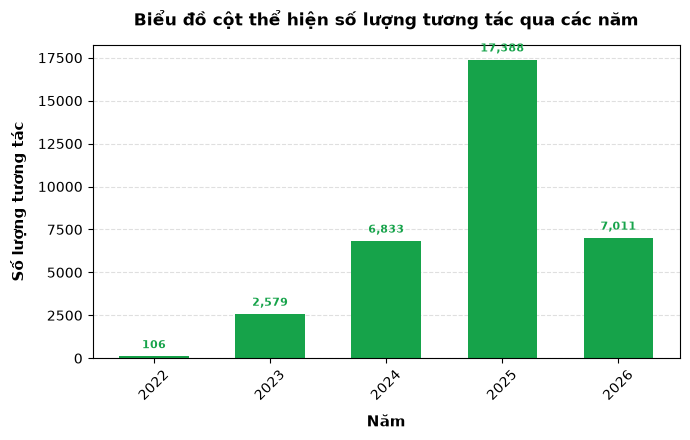

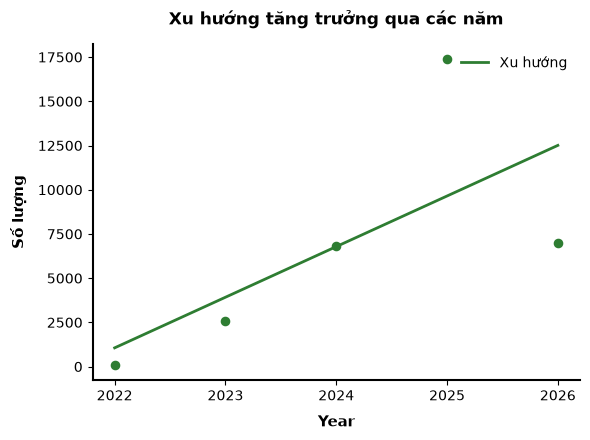

In [2]:
df_raw["commit_date"] = pd.to_datetime(df_raw["commit_date"], utc=True)
df_raw['Year'] = df_raw["commit_date"].dt.year
df_raw['Hour'] = df_raw["commit_date"].dt.hour
df_raw['Day_of_Week'] = df_raw['commit_date'].dt.day_name()

year_counting = df_raw.groupby("Year", as_index=False).size()
year_count = pd.DataFrame({
    'Năm': year_counting["Year"],
    'Số lượng': year_counting["size"],
    'Tỉ lệ (%)': (year_counting["size"] / len(df_raw) * 100).round(2)
})

# PillarChart-------------------------------
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(
    year_count['Năm'],
    year_count['Số lượng'],
    color='#16a34a',
    width=0.6,
    zorder=2
)

# Gắn giá trị cụ thể lên đỉnh tất cả các cột
for bar in bars:
    height = bar.get_height()
    if height > 0:
        ax.annotate(
            f'{height:,}',
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 4),
            textcoords="offset points",
            ha='center', va='bottom',
            fontsize=8, fontweight='bold', color='#16a34a'
        )

ax.set_xlabel("Năm", fontsize=11, fontweight='bold', labelpad=8)
ax.set_ylabel("Số lượng tương tác", fontsize=11, fontweight='bold', labelpad=8)
ax.set_title("Biểu đồ cột thể hiện số lượng tương tác qua các năm", fontsize=12, fontweight='bold', pad=14)

# Bật lưới ngang mờ để dễ gióng giá trị
ax.grid(axis='y', linestyle='--', alpha=0.4, zorder=1)

# Hiển thị đầy đủ các năm trên trục X
plt.xticks(year_count['Năm'], rotation=45)
plt.tight_layout()
plt.show()

# ScatterPlot------------------------------------
x = year_count['Năm'].astype(float)
y = year_count['Số lượng'].astype(float)
fig, ax = plt.subplots(figsize=(6, 4.5))

# 1. Tính toán đường xu hướng tuyến tính (Linear Regression)
m, b = np.polyfit(x, y, 1)
# 2. Vẽ đường xu hướng (Trendline) màu xanh lá
ax.plot(x, m * x + b, color='#2e7d32', linewidth=2, label='Xu hướng', zorder=2)
# 3. Vẽ các điểm Scatter plot màu xanh lá
ax.scatter(x, y, color='#2e7d32', s=35, zorder=3)

# Bỏ khung phía trên và bên phải
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Làm đậm trục X và Y bên trái/dưới
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

# Đặt nhãn tên trục và tiêu đề
ax.set_xlabel("Year", fontsize=11, fontweight='bold', labelpad=8)
ax.set_ylabel("Số lượng", fontsize=11, fontweight='bold', labelpad=8)
ax.set_title("Xu hướng tăng trưởng qua các năm", fontsize=12, fontweight='bold', pad=14)
ax.legend(frameon=False)

plt.xticks(year_count['Năm'].astype(int))
plt.tight_layout()
plt.show()

---
# BLOCK 2 — Trực quan hóa tỷ lệ và số lượng ngôn ngữ lập trình
---

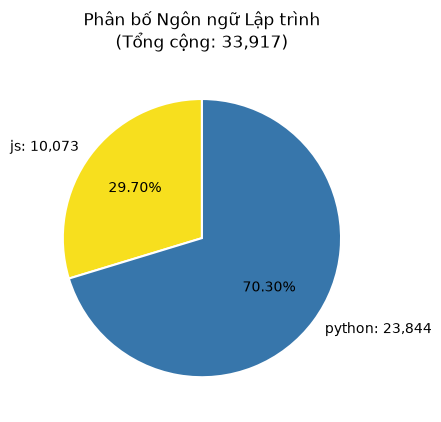

In [3]:
language_counting = df_raw.groupby("language", as_index=False).size()
language_count = pd.DataFrame({
    'Ngôn ngữ': language_counting["language"],
    'Số lượng': language_counting["size"],
    'Tỉ lệ (%)': (language_counting["size"] / len(df_raw) * 100).round(2)
})

color_map = {
    'js': '#F7DF1E',
    'python': '#3776AB'
}
colors = [color_map.get(str(lang).lower(), '#999999') for lang in language_count['Ngôn ngữ']]

total_samples = language_count['Số lượng'].sum()

fig, ax = plt.subplots(figsize=(4.5, 4.5))

# Nhãn tên ngôn ngữ kết hợp số lượng ở bên ngoài
external_labels = [
    f"{row['Ngôn ngữ']}: {row['Số lượng']:,}"
    for _, row in language_count.iterrows()
]

ax.pie(
    language_count['Số lượng'],
    labels=external_labels,
    autopct='%1.2f%%',
    startangle=90,
    colors=colors,
    pctdistance=0.6,
    wedgeprops=dict(edgecolor='white', linewidth=1.5)
)

# Tiêu đề kèm tổng số mẫu
ax.set_title(
    f"Phân bố Ngôn ngữ Lập trình\n(Tổng cộng: {total_samples:,})",
    pad=12
)

plt.tight_layout()
plt.show()

---
# BLOCK 3 — Trực quan hóa Phân bố theo Thời gian (Giờ & Thứ)
---

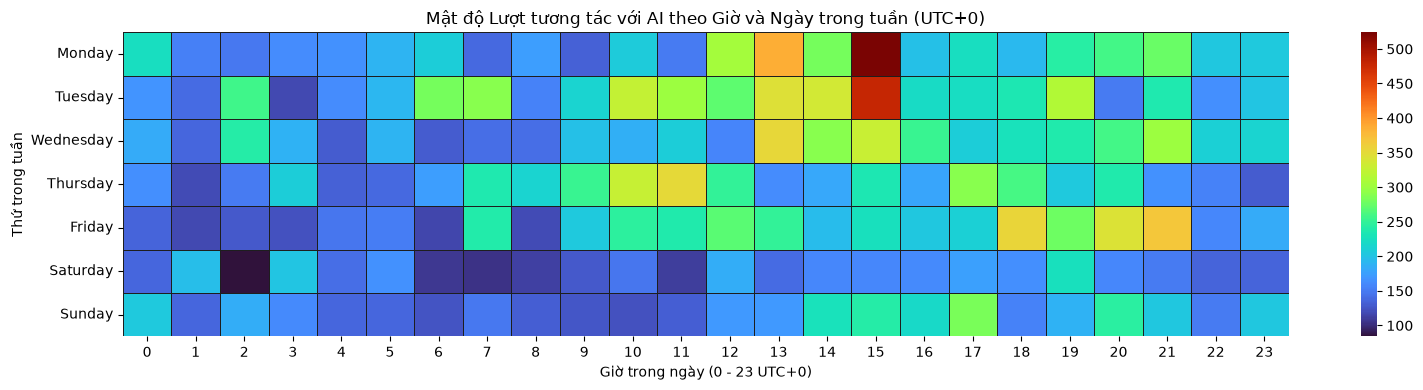

In [4]:
heatmap_data = df_raw.pivot_table(
    index='Day_of_Week',
    columns='Hour',
    values='commit_date',
    aggfunc='count',
    fill_value=0
)

days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
hours_order = list(range(24))

heatmap_data = heatmap_data.reindex(index=days_order, columns=hours_order, fill_value=0)

plt.figure(figsize=(16, 4))
sns.heatmap(heatmap_data, cmap='turbo', linewidths=0.5, linecolor='#1e1e1e')
plt.title('Mật độ Lượt tương tác với AI theo Giờ và Ngày trong tuần (UTC+0)')
plt.xlabel('Giờ trong ngày (0 - 23 UTC+0)')
plt.ylabel('Thứ trong tuần')
plt.tight_layout()
plt.show()